# Chapitre 4 - Cours 4 : Concevoir un pipeline d'évaluation

Les benchmarks publics éliminent les mauvais modèles ; pour trouver le bon et guider le
développement dans la durée, il faut **son propre pipeline d'évaluation**. Ce notebook suit
la section *Design Your Evaluation Pipeline* du livre, centrée sur les tâches ouvertes :

1. vue d'ensemble du pipeline ;
2. étape 1 : évaluer chaque composant, par tour et par tâche (section *Step 1. Evaluate All Components in a System*) ;
3. étape 2 : lignes directrices, rubriques et métriques métier (section *Step 2. Create an Evaluation Guideline*) ;
4. étape 3 : choisir les méthodes, exploiter les logprobs (section *Select evaluation methods*) ;
5. découper par tranches et le paradoxe de Simpson (section *Annotate evaluation data*) ;
6. combien d'exemples ? bootstrap et taille d'échantillon ;
7. évaluer le pipeline d'évaluation (section *Evaluate your evaluation pipeline*) ;
8. itérer et tracer les expériences (section *Iterate*).

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.ticker import FuncFormatter
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.max_colwidth", 80)
llm.seed_everything(0)

## 1. Vue d'ensemble du pipeline (section *Design Your Evaluation Pipeline*)

Le succès d'une application d'IA tient souvent à sa capacité à **distinguer les bons
résultats des mauvais**. Le livre propose trois étapes, suivies d'une méta-évaluation et
d'une itération permanente. Le diagramme ci-dessous en donne la carte ; chaque section du
notebook en détaille une boîte.

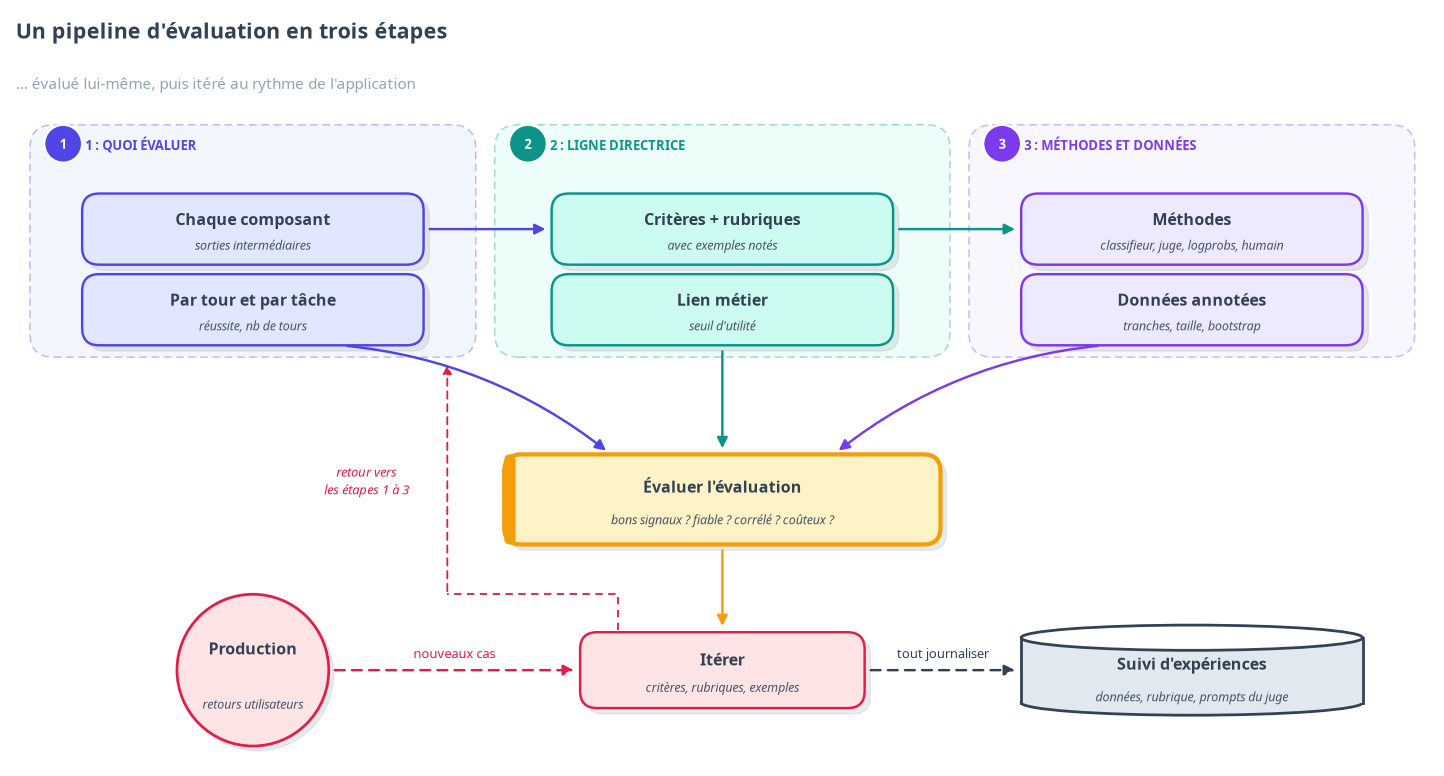

In [2]:
d = Diagram(15, 7.0, title="Un pipeline d'évaluation en trois étapes",
            subtitle="... évalué lui-même, puis itéré au rythme de l'application")
d.group(0.2, 4.3, 4.9, 6.75, "étape 1 : quoi évaluer", color=INDIGO)
d.group(5.1, 4.3, 9.9, 6.75, "étape 2 : ligne directrice", color=TEAL)
d.group(10.1, 4.3, 14.8, 6.75, "étape 3 : méthodes et données", color=VIOLET)
d.box("c1", 2.55, 5.65, "Chaque composant", sub="sorties intermédiaires", color=INDIGO, w=3.6, h=0.75)
d.box("c2", 2.55, 4.8, "Par tour et par tâche", sub="réussite, nb de tours", color=INDIGO, w=3.6, h=0.75)
d.box("g1", 7.5, 5.65, "Critères + rubriques", sub="avec exemples notés", color=TEAL, w=3.6, h=0.75)
d.box("g2", 7.5, 4.8, "Lien métier", sub="seuil d'utilité", color=TEAL, w=3.6, h=0.75)
d.box("m1", 12.45, 5.65, "Méthodes", sub="classifieur, juge, logprobs, humain", color=VIOLET, w=3.6, h=0.75)
d.box("m2", 12.45, 4.8, "Données annotées", sub="tranches, taille, bootstrap", color=VIOLET, w=3.6, h=0.75)
d.box("meta", 7.5, 2.8, "Évaluer l'évaluation", sub="bons signaux ? fiable ? corrélé ? coûteux ?", color=AMBER,
      w=4.6, h=0.95, kind="model")
d.box("prod", 2.55, 1.0, "Production", sub="retours utilisateurs", color=ROSE, kind="user", w=1.6)
d.box("log", 12.45, 1.0, "Suivi d'expériences", sub="données, rubrique, prompts du juge", color=SLATE, kind="db", w=3.6, h=0.95)
d.box("it", 7.5, 1.0, "Itérer", sub="critères, rubriques, exemples", color=ROSE, w=3.0, h=0.8)
d.arrow("c1", "g1", color=INDIGO); d.arrow("g1", "m1", color=TEAL)
d.arrow("g2", "meta", color=TEAL); d.arrow("m2", "meta", color=VIOLET, rad=0.15); d.arrow("c2", "meta", color=INDIGO, rad=-0.15)
d.arrow("meta", "it", color=AMBER)
d.arrow("it", "log", "tout journaliser", color=SLATE, style="dashed")
d.arrow("prod", "it", "nouveaux cas", color=ROSE, style="dashed")
d.line([(6.4, 1.42), (6.4, 1.8), (4.6, 1.8), (4.6, 4.25)], color=ROSE, style="dashed")
d.note(3.75, 3.0, "retour vers\nles étapes 1 à 3", color=ROSE, fontsize=8.5)
d.badge(0.55, 6.55, "1", INDIGO); d.badge(5.45, 6.55, "2", TEAL); d.badge(10.45, 6.55, "3", VIOLET)
d.show()

> **À retenir.** Un pipeline d'évaluation fiable répond à trois questions (quoi évaluer,
> qu'est-ce qu'une bonne réponse, avec quelles méthodes et quelles données), puis s'évalue
> lui-même et s'itère sous suivi d'expériences.

## 2. Étape 1 : évaluer chaque composant, par tour et par tâche (section *Step 1*)

**Évaluer chaque composant.** Reprenons l'exemple du livre : extraire l'employeur actuel
d'une personne à partir de son CV en PDF, en deux étapes : (1) PDF vers texte ; (2) extraction
de l'employeur depuis le texte. Si la sortie finale est fausse, laquelle des deux étapes a
échoué ? Sans évaluation par composant, impossible de le savoir. On évalue :

- l'étape 1 par la **similarité** entre le texte extrait et le texte de référence ;
- l'étape 2 par l'**exactitude** *sachant un texte correct* ;
- le système complet de bout en bout.

On simule l'étape 1 par une extraction bruitée (caractères confondus comme `l`/`1` ou
`e`/`c`, espaces perdues) à différents taux d'erreur, et l'étape 2 est confiée à Qwen 0.5B.

In [3]:
cvs = c4.make_resumes(16, seed=0)
print(cvs[0]["texte"]); print("-> employeur attendu :", cvs[0]["employeur"])
print("\nAvec 8 % de bruit d'extraction :\n" + c4.ocr_noise(cvs[0]["texte"], 0.08, seed=0)[:220], "...")

Claire Benali
Courriel : claire@exemple.fr

EXPÉRIENCE PROFESSIONNELLE
- 2008 - 2010 : chef de projet chez Sanofi
- depuis 2012 (poste actuel) : développeur web chez Alstom
- 2010 - 2012 : consultant chez Thales

FORMATION
- Master obtenu en 2007

LANGUES : français, anglais
-> employeur attendu : Alstom

Avec 8 % de bruit d'extraction :
Clolre Bena1i
Courricl : claire@exemple.fr

EXPÉRIENCE PROFESSIONNELLE
- 2008 - 2010 : chef de projet chez Sonofi
- dcpvis 2012 (poste actuel) : dével0ppeur web chez Alstom
- 2010 - 2012 : consultont chez Tholes

FORMATI ...


In [4]:
q = ("Voici un CV.\n\n{cv}\n\nQuel est l'employeur actuel de cette personne ? "
     "Réponds uniquement par le nom de l'entreprise.")
rates = [0.0, 0.03, 0.08, 0.15, 0.25]
rows = []
for r in rates:
    texts = [c4.ocr_noise(cv["texte"], r, seed=i) for i, cv in enumerate(cvs)]
    preds = c4.chat_batch([q.format(cv=t) for t in texts], llm.SMALL, max_new_tokens=12)
    for cv, t, p in zip(cvs, texts, preds):
        rows.append(dict(bruit=r, sim=c4.text_similarity(t, cv["texte"]),
                         ok=c4.answer_match(p, cv["employeur"]), pred=p))
comp = pd.DataFrame(rows)
etape2 = comp[comp.bruit == 0].ok.mean()                 # étape 2 seule, sur texte parfait
agg = comp.groupby("bruit").agg(similarite_etape1=("sim", "mean"), exactitude_bout_en_bout=("ok", "mean"))
agg["exactitude_etape2_isolee"] = etape2
agg.round(3)

,similarite_etape1,exactitude_bout_en_bout,exactitude_etape2_isolee
bruit,,,
0.00,1.000,0.875,0.875
0.03,0.957,0.688,0.875
0.08,0.885,0.312,0.875
0.15,0.798,0.188,0.875
0.25,0.686,0.250,0.875


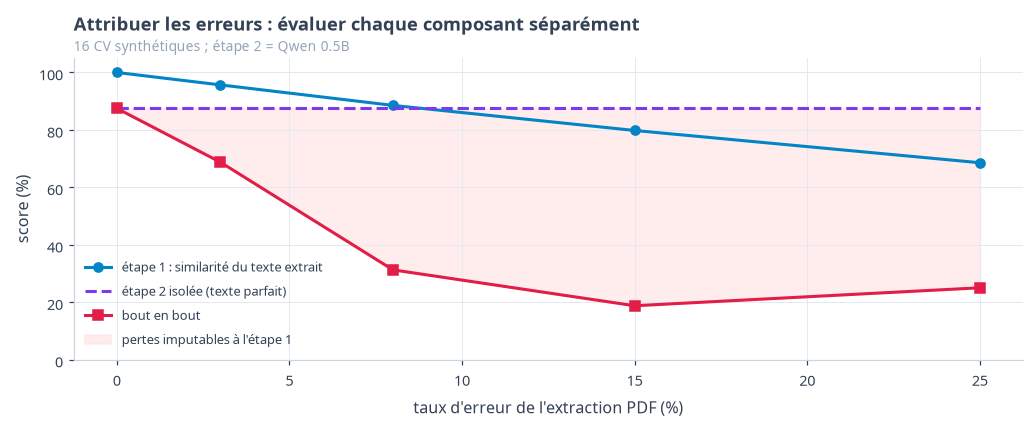

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.array(rates) * 100
ax.plot(x, agg.similarite_etape1 * 100, "o-", color=SKY, label="étape 1 : similarité du texte extrait")
ax.plot(x, agg.exactitude_etape2_isolee * 100, "--", color=VIOLET, label="étape 2 isolée (texte parfait)")
ax.plot(x, agg.exactitude_bout_en_bout * 100, "s-", color=ROSE, label="bout en bout")
ax.fill_between(x, agg.exactitude_bout_en_bout * 100, agg.exactitude_etape2_isolee * 100, color=LIGHT[ROSE],
                alpha=0.7, label="pertes imputables à l'étape 1")
ax.set_xlabel("taux d'erreur de l'extraction PDF (%)"); ax.set_ylabel("score (%)"); ax.set_ylim(0, 105)
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Attribuer les erreurs : évaluer chaque composant séparément", pad=18)
subtitle(ax, f"{len(cvs)} CV synthétiques ; étape 2 = Qwen 0.5B")
plt.tight_layout(); plt.show()

L'écart entre l'étape 2 isolée et le bout en bout est imputable à l'extraction : si l'étape 2
isolée est déjà médiocre, inutile d'améliorer l'OCR en premier ; si elle est bonne mais que
le bout en bout s'effondre avec le bruit, c'est l'extraction qu'il faut soigner. Avec un modèle
de 0,5 milliard de paramètres, l'étape 2 n'est pas parfaite même sur texte propre : il
confond parfois un ancien employeur et l'actuel (lire « depuis ... (poste actuel) » demande
un peu de raisonnement).

**Par tour et par tâche.** Un **tour** peut contenir plusieurs étapes ; une **tâche** peut
demander plusieurs tours (le modèle demande la version de Python avant de déboguer). L'évaluation
par tâche est la plus importante (l'utilisateur veut que sa tâche aboutisse) et compte aussi le
**nombre de tours** : résoudre en 2 tours ou en 20 change tout. Le livre cite le benchmark
*twenty_questions* de BIG-bench : un joueur pense à un objet, l'autre doit le deviner par des
questions oui/non. Simulons deux questionneurs sur 16 objets décrits par 10 attributs.

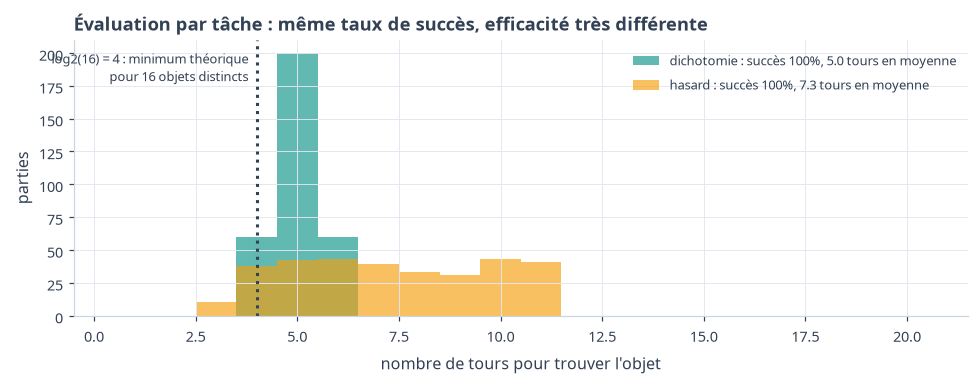

In [6]:
games = []
for strat in ["dichotomie", "hasard"]:
    for seed in range(20):
        for obj in c4.TWENTY_Q_OBJECTS:
            ok, turns = c4.play_twenty_questions(obj, strat, seed=seed)
            games.append(dict(stratégie=strat, objet=obj, succès=ok, tours=turns))
games = pd.DataFrame(games)
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(1, 22) - 0.5
for strat, c in [("dichotomie", TEAL), ("hasard", AMBER)]:
    g = games[games.stratégie == strat]
    ax.hist(g.tours, bins=bins, color=c, alpha=0.65, label=f"{strat} : succès {g.succès.mean():.0%}, "
            f"{g.tours.mean():.1f} tours en moyenne")
ax.axvline(np.log2(16), color=SLATE, ls=":")
ax.text(np.log2(16) - 0.2, ax.get_ylim()[1] * 0.85, "log2(16) = 4 : minimum théorique\npour 16 objets distincts",
        fontsize=8.5, ha="right")
ax.set_xlabel("nombre de tours pour trouver l'objet"); ax.set_ylabel("parties")
ax.set_title("Évaluation par tâche : même taux de succès, efficacité très différente"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Les deux questionneurs finissent par trouver (succès identique), mais la dichotomie y arrive
en moins de tours et avec une dispersion bien plus faible (le hasard pose souvent des
questions inutiles) : une métrique de succès seule masquerait cette différence. Notez
que certains objets partagent tous leurs attributs (pomme, fraise et carotte sont ici
indiscernables) : il faut alors deviner, ce qui ajoute des tours, même avec la meilleure
stratégie. La difficulté pratique de l'évaluation par tâche est ailleurs : dans une vraie
conversation, où s'arrête une tâche et où commence la suivante ?

> **À retenir.** Évaluez chaque composant séparément (sinon vous ne savez pas où le système
> échoue), et le système entier par tâche, en comptant les tours, pas seulement le succès.

## 3. Étape 2 : lignes directrices, rubriques, métriques métier (section *Step 2*)

C'est **l'étape la plus importante** selon le livre : une ligne directrice ambiguë produit
des scores ambigus. Elle définit ce que l'application doit faire **et ce qu'elle ne doit pas
faire** (un chatbot de support doit-il parler des élections ?). LinkedIn rapporte que la
première difficulté a été de définir une bonne réponse : « vous ne correspondez pas du tout
au poste » peut être correct, mais n'est pas utile.

**Critères.** Pour un support client, par exemple : pertinence, cohérence factuelle,
sécurité (les utilisateurs de LangChain combinent en moyenne 2,3 types de retour). **Rubrique.**
Pour chaque critère, un système de notation (binaire, -1/0/1, 1 à 5...) et des **exemples
notés** qui justifient chaque note, validés par plusieurs humains : si eux-mêmes ne sont pas
d'accord, la rubrique est à reprendre.

In [7]:
rubrique = pd.DataFrame([
    (-1, "contradiction", "Au moins une affirmation contredit le contexte.",
     "« La médiathèque est ouverte le dimanche. »"),
    (0, "neutre", "Aucune contradiction, mais des affirmations invérifiables dans le contexte.",
     "« La médiathèque possède un café. »"),
    (1, "implication", "Toutes les affirmations se déduisent du contexte.",
     "« Les mineurs s'inscrivent gratuitement. »"),
], columns=["note", "étiquette", "définition", "exemple (contexte : fiche de la médiathèque)"])
rubrique

,note,étiquette,définition,exemple (contexte : fiche de la médiathèque)
0,-1,contradiction,Au moins une affirmation contredit le contexte.,« La médiathèque est ouverte le dimanche. »
1,0,neutre,"Aucune contradiction, mais des affirmations invérifiables dans le contexte.",« La médiathèque possède un café. »
2,1,implication,Toutes les affirmations se déduisent du contexte.,« Les mineurs s'inscrivent gratuitement. »


**Relier aux métriques métier.** Que signifie une cohérence factuelle de 80 % pour
l'entreprise ? Le livre propose de construire une correspondance entre métrique d'évaluation
et métrique métier (ici, la part des demandes de support automatisables), et d'en déduire un
**seuil d'utilité** en dessous duquel l'application est inutilisable.

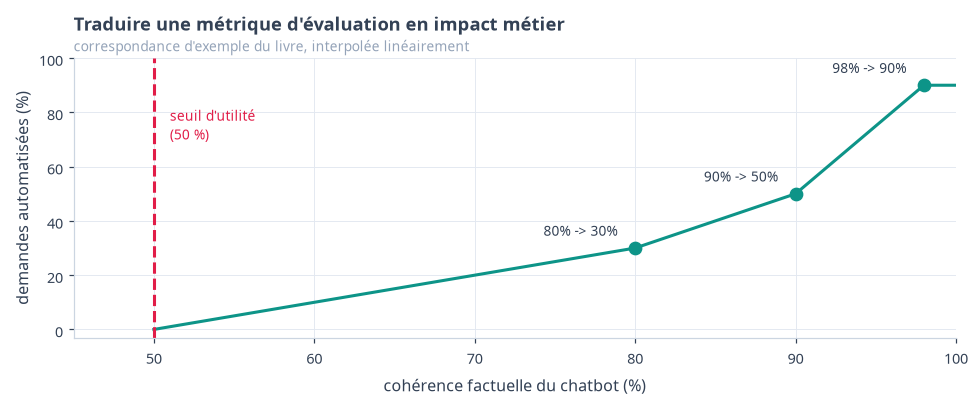

In [8]:
fc = np.array([0.5, 0.8, 0.9, 0.98])
auto = np.array([0.0, 0.30, 0.50, 0.90])
xs = np.linspace(0.5, 1.0, 200)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(xs * 100, np.interp(xs, fc, auto) * 100, color=TEAL)
ax.plot(fc[1:] * 100, auto[1:] * 100, "o", color=TEAL, ms=8)
for f, a in zip(fc[1:], auto[1:]):
    ax.annotate(f"{f:.0%} -> {a:.0%}", (f * 100, a * 100), xytext=(-60, 8), textcoords="offset points", fontsize=9)
ax.axvline(50, color=ROSE, ls="--"); ax.text(51, 70, "seuil d'utilité\n(50 %)", color=ROSE, fontsize=9)
ax.set_xlabel("cohérence factuelle du chatbot (%)"); ax.set_ylabel("demandes automatisées (%)")
ax.set_xlim(45, 100); ax.set_ylim(-3, 100)
ax.set_title("Traduire une métrique d'évaluation en impact métier", pad=18)
subtitle(ax, "correspondance d'exemple du livre, interpolée linéairement")
plt.tight_layout(); plt.show()

La courbe est convexe : les derniers points de cohérence factuelle valent beaucoup plus que
les premiers (passer de 90 à 98 % fait passer l'automatisation de 50 à 90 %). Cette
correspondance permet de **chiffrer l'intérêt** d'un investissement d'amélioration. Le livre
invite aussi à réfléchir aux métriques métier visées (utilisateurs actifs, engagement) et à
leurs effets pervers (fonctionnalités addictives).

> **À retenir.** Une bonne ligne directrice définit les critères, une rubrique avec exemples
> validée par des humains, et une correspondance avec les métriques métier assortie d'un seuil
> d'utilité.

## 4. Étape 3 : choisir les méthodes, exploiter les logprobs (section *Select evaluation methods*)

Chaque critère appelle sa méthode : un petit classifieur pour la toxicité, la similarité
sémantique pour la pertinence, une IA juge pour la cohérence factuelle avec un long contexte.
On peut **mélanger** : un classifieur bon marché sur 100 % du trafic et un juge coûteux sur 1 %.

**Quand les logprobs sont disponibles, utilisez-les.** Pour une classification, la probabilité
de chaque classe mesure la **confiance** du modèle : des probabilités de 30 à 40 % pour trois
classes signalent une hésitation, 95 % une décision franche. Testons sur 30 messages de clients
(dont quelques ironiques), classés par Qwen 0.5B : pour chaque étiquette, on somme les
log-probabilités de ses tokens comme réponse de l'assistant, puis on renormalise sur les trois
étiquettes (une étiquette comme « négatif » occupe plusieurs tokens).

exactitude globale : 57%


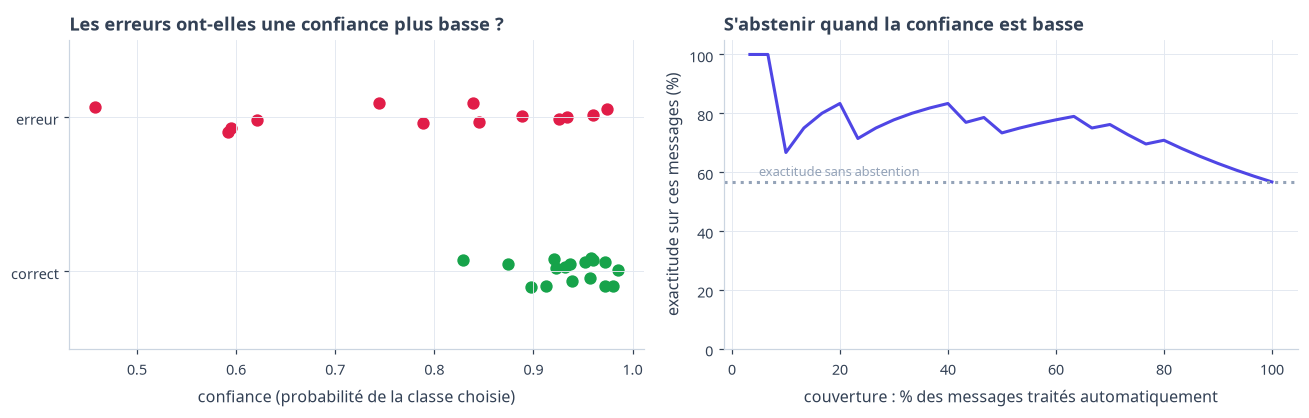

In [9]:
labels = ["positif", "négatif", "neutre"]
prompt = ("Classe le sentiment de ce message de client. Réponds par un seul mot : positif, négatif ou neutre.\n"
          "Message : {m}")
P = np.array([c4.option_probs(prompt.format(m=m), labels, llm.SMALL) for m, _ in c4.SENTIMENT_SET])
gold = np.array([{"positif": 0, "negatif": 1, "neutre": 2}[g] for _, g in c4.SENTIMENT_SET])
pred, conf = P.argmax(1), P.max(1)
correct = pred == gold
print(f"exactitude globale : {correct.mean():.0%}")
order = np.argsort(-conf)
cov = np.arange(1, len(order) + 1) / len(order)
sel_acc = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].scatter(conf[correct], np.zeros(correct.sum()) + 0.1 * np.random.default_rng(0).uniform(-1, 1, correct.sum()),
                color=GREEN, s=50, label="bonne réponse")
axes[0].scatter(conf[~correct], np.ones((~correct).sum()) + 0.1 * np.random.default_rng(1).uniform(-1, 1, (~correct).sum()),
                color=ROSE, s=50, label="erreur")
axes[0].set_yticks([0, 1], ["correct", "erreur"]); axes[0].set_xlabel("confiance (probabilité de la classe choisie)")
axes[0].set_title("Les erreurs ont-elles une confiance plus basse ?"); axes[0].set_ylim(-0.5, 1.5)
axes[1].plot(cov * 100, sel_acc * 100, color=INDIGO)
axes[1].axhline(correct.mean() * 100, color=GRAY, ls=":")
axes[1].text(5, correct.mean() * 100 + 2, "exactitude sans abstention", fontsize=8.5, color=GRAY)
axes[1].set_xlabel("couverture : % des messages traités automatiquement")
axes[1].set_ylabel("exactitude sur ces messages (%)"); axes[1].set_ylim(0, 105)
axes[1].set_title("S'abstenir quand la confiance est basse")
finish(fig)

Si les erreurs se concentrent aux confiances basses, on peut traiter automatiquement les cas
confiants et **router les autres vers un humain ou un juge plus coûteux** : c'est la courbe
exactitude / couverture. Sur un modèle aussi petit, la confiance n'est qu'imparfaitement
informative (les messages ironiques peuvent être classés « positif » avec assurance) : il faut
vérifier cette propriété sur ses propres données avant de s'y fier.

**Le coût d'un mélange de méthodes.** Pour 1 million de réponses par mois, comparons trois
stratégies (prix fictifs mais réalistes en ordre de grandeur).

In [10]:
N = 1_000_000
strat = pd.DataFrame([
    ("classifieur seul (100 %)", 1.0, 0.0, 0.0),
    ("classifieur 100 % + juge 1 %", 1.0, 0.01, 0.0),
    ("juge sur 100 %", 0.0, 1.0, 0.0),
    ("classifieur 100 % + juge 1 % + humain 500/jour", 1.0, 0.01, 15_000 / N),
], columns=["stratégie", "part_classifieur", "part_juge", "part_humain"])
cout_unit = dict(classifieur=0.00002, juge=0.004, humain=0.50)   # $ par réponse évaluée
strat["coût mensuel ($)"] = N * (strat.part_classifieur * cout_unit["classifieur"] + strat.part_juge * cout_unit["juge"]
                                + strat.part_humain * cout_unit["humain"])
strat[["stratégie", "coût mensuel ($)"]].round(0)

,stratégie,coût mensuel ($)
0,classifieur seul (100 %),20.0
1,classifieur 100 % + juge 1 %,60.0
2,juge sur 100 %,4000.0
3,classifieur 100 % + juge 1 % + humain 500/jour,7560.0


Le juge sur 1 % du trafic coûte peu et apporte un signal de qualité régulier ; le juge sur
100 % coûte deux ordres de grandeur de plus. L'évaluation humaine reste l'**étoile polaire** :
LinkedIn faisait évaluer manuellement jusqu'à 500 conversations par jour. En production, on n'a
plus de références mais on a des utilisateurs : prévoir quels retours collecter (chapitre 10).

> **À retenir.** Choisissez une méthode par critère, combinez méthodes bon marché à large
> couverture et méthodes coûteuses sur échantillon, exploitez les logprobs pour mesurer la
> confiance, et gardez des humains dans la boucle.

## 5. Découper par tranches et le paradoxe de Simpson (section *Annotate evaluation data*)

Utilisez de préférence des données de production, annotées selon la rubrique. Puis
**découpez** : regarder la performance par sous-ensemble (offre gratuite / payante, mobile /
web, longueur, sujet...) permet de détecter des biais contre des groupes minoritaires, de
déboguer, de trouver des pistes d'amélioration, et d'éviter le **paradoxe de Simpson** : un
modèle A meilleur que B dans **chaque** groupe peut être moins bon **au global**. L'exemple du
livre (tableau 4-6, chiffres d'une étude médicale de 1986) :

In [11]:
counts = {"Modèle A": {"groupe 1": (81, 87), "groupe 2": (192, 263)},
          "Modèle B": {"groupe 1": (234, 270), "groupe 2": (55, 80)}}
tab = c4.simpson_table(counts)
print("Paradoxe de Simpson détecté :", c4.is_simpson(counts))
(tab * 100).round(1)

Paradoxe de Simpson détecté : True


,groupe 1,groupe 2,global
Modèle A,93.1,73.0,78.0
Modèle B,86.7,68.8,82.6


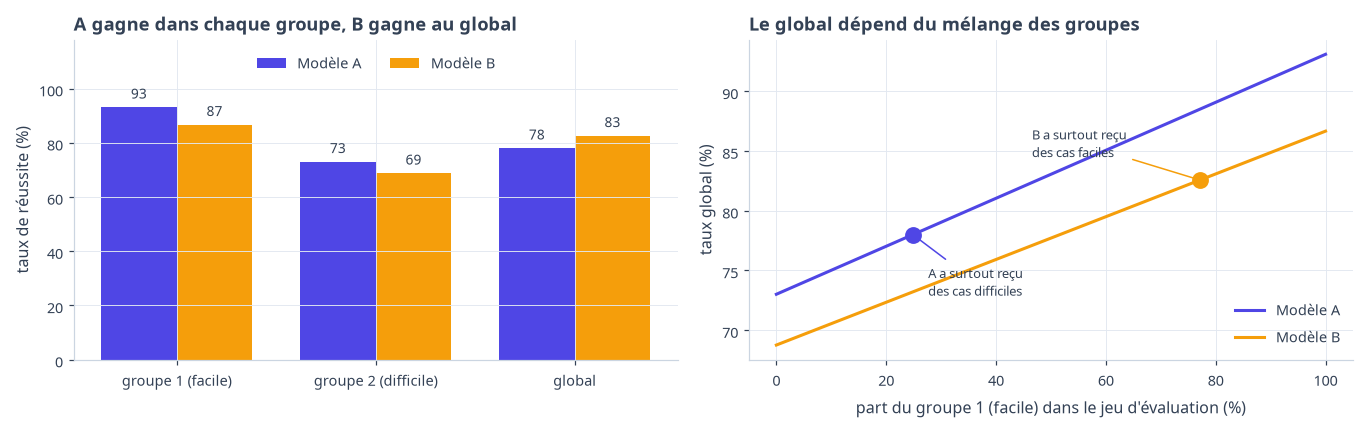

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
ax = axes[0]
x = np.arange(3)
for j, (mname, c) in enumerate([("Modèle A", INDIGO), ("Modèle B", AMBER)]):
    ax.bar(x + (j - 0.5) * 0.38, tab.loc[mname] * 100, width=0.38, color=c, label=mname)
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x, ["groupe 1 (facile)", "groupe 2 (difficile)", "global"]); ax.set_ylim(0, 118)
ax.set_ylabel("taux de réussite (%)"); ax.legend(loc="upper center", ncol=2)
ax.set_title("A gagne dans chaque groupe, B gagne au global")
ax = axes[1]
share = np.linspace(0, 1, 101)
for mname, c in [("Modèle A", INDIGO), ("Modèle B", AMBER)]:
    ax.plot(share * 100, (share * tab.loc[mname, "groupe 1"] + (1 - share) * tab.loc[mname, "groupe 2"]) * 100,
            color=c, label=mname)
nA, nB = 87 / 350, 270 / 350
ax.plot(nA * 100, tab.loc["Modèle A", "global"] * 100, "o", color=INDIGO, ms=10)
ax.plot(nB * 100, tab.loc["Modèle B", "global"] * 100, "o", color=AMBER, ms=10)
ax.annotate("A a surtout reçu\ndes cas difficiles", (nA * 100, tab.loc["Modèle A", "global"] * 100), xytext=(10, -40),
            textcoords="offset points", fontsize=8.5, arrowprops=dict(arrowstyle="-", color=INDIGO))
ax.annotate("B a surtout reçu\ndes cas faciles", (nB * 100, tab.loc["Modèle B", "global"] * 100), xytext=(-110, 15),
            textcoords="offset points", fontsize=8.5, arrowprops=dict(arrowstyle="-", color=AMBER))
ax.set_xlabel("part du groupe 1 (facile) dans le jeu d'évaluation (%)"); ax.set_ylabel("taux global (%)")
ax.set_title("Le global dépend du mélange des groupes"); ax.legend(loc="lower right")
finish(fig)

L'explication est visible à droite : à mélange égal, A est toujours au-dessus de B (sa droite
domine), mais A a été évalué sur 75 % de cas difficiles, B sur 77 % de cas faciles. Le taux
global compare donc des **mélanges** différents, pas des modèles. Deux remèdes : comparer les
modèles **sur les mêmes exemples** (évaluation appariée), et rapporter le global **pondéré par
la distribution de production**, par exemple
$$\text{score}_{\text{prod}} = \sum_g \pi_g\, \text{score}_g,$$
où $\pi_g$ est la part du groupe $g$ dans le trafic réel.

In [13]:
for pi1 in [0.3, 0.5, 0.8]:
    s = {m: pi1 * tab.loc[m, "groupe 1"] + (1 - pi1) * tab.loc[m, "groupe 2"] for m in tab.index}
    print(f"production avec {pi1:.0%} de groupe 1 : A = {s['Modèle A']:.1%}, B = {s['Modèle B']:.1%}")

production avec 30% de groupe 1 : A = 79.0%, B = 74.1%
production avec 50% de groupe 1 : A = 83.1%, B = 77.7%
production avec 80% de groupe 1 : A = 89.1%, B = 83.1%


Le livre recommande plusieurs jeux d'évaluation : un qui reflète la distribution de
production, un par tranche importante, un d'erreurs fréquentes du système, un d'erreurs
fréquentes des utilisateurs (fautes de frappe), un hors périmètre. Sa devise : **si une chose
compte pour vous, mettez un jeu de test dessus.**

> **À retenir.** Découpez systématiquement vos résultats par tranches. Un score global compare
> des mélanges : comparez sur les mêmes exemples et pondérez par la distribution de production.

## 6. Combien d'exemples ? Bootstrap et taille d'échantillon (section *Annotate evaluation data*)

**Le bootstrap.** Avec 100 exemples, le score est-il fiable ? Le livre propose de tirer
100 exemples **avec remise** parmi les 100, de recalculer le score, et de recommencer : si les
scores varient de 70 à 90 %, l'évaluation n'est pas fiable. Les quantiles 2,5 % et 97,5 % de
ces scores forment un **intervalle de confiance à 95 %**. Pour un score binaire d'exactitude
$p$, la théorie donne la largeur attendue
$$\text{IC}_{95\%} \approx p \pm 1{,}96\sqrt{\frac{p(1-p)}{n}}.$$

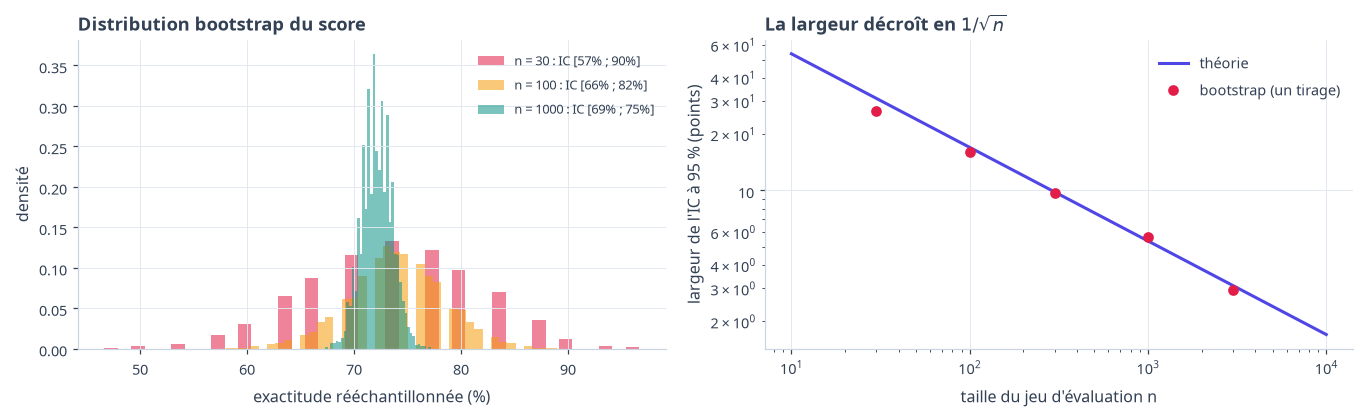

In [14]:
rng = np.random.default_rng(0)
true_p = 0.75
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
ns = [30, 100, 1000]
for n, c in zip(ns, [ROSE, AMBER, TEAL]):
    sample = rng.random(n) < true_p
    idx = rng.integers(0, n, size=(3000, n))
    boots = sample[idx].mean(1)
    m, lo, hi = c4.bootstrap_ci(sample, seed=1)
    axes[0].hist(boots * 100, bins=40, color=c, alpha=0.55, density=True, label=f"n = {n} : IC [{lo:.0%} ; {hi:.0%}]")
axes[0].set_xlabel("exactitude rééchantillonnée (%)"); axes[0].set_ylabel("densité")
axes[0].set_title("Distribution bootstrap du score"); axes[0].legend(fontsize=8.5)
n_grid = np.logspace(1, 4, 50)
axes[1].plot(n_grid, 2 * 1.96 * np.sqrt(true_p * (1 - true_p) / n_grid) * 100, color=INDIGO, label="théorie")
emp = [np.subtract(*c4.bootstrap_ci(rng.random(int(n)) < true_p, n_boot=800, seed=2)[2:0:-1]) * 100
       for n in [10, 30, 100, 300, 1000, 3000]]
axes[1].plot([10, 30, 100, 300, 1000, 3000], emp, "o", color=ROSE, label="bootstrap (un tirage)")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
axes[1].set_xlabel("taille du jeu d'évaluation n"); axes[1].set_ylabel("largeur de l'IC à 95 % (points)")
axes[1].set_title(r"La largeur décroît en $1/\sqrt{n}$"); axes[1].legend()
finish(fig)

Avec 30 exemples, l'intervalle couvre plus de 30 points : on ne peut presque rien conclure.
Il faut **quadrupler** $n$ pour diviser la largeur par deux.

**Comparer deux systèmes.** La vraie question est souvent : le nouveau prompt est-il
meilleur ? Pour détecter une différence $\Delta$ entre deux taux voisins de $p$ (test bilatéral
à 5 %, puissance 80 %), sur deux jeux indépendants :
$$n \approx \frac{(z_{0,975} + z_{0,8})^2 \cdot 2p(1-p)}{\Delta^2} \approx \frac{15{,}7\,p(1-p)}{\Delta^2}.$$
Le facteur $1/\Delta^2$ explique la règle d'OpenAI citée par le livre (tableau 4-7) : diviser
l'écart à détecter par 3 multiplie le nombre d'exemples par $3^2 \approx 10$.

In [15]:
deltas = [0.30, 0.10, 0.03, 0.01]
openai = [10, 100, 1000, 10000]
t47 = pd.DataFrame(dict(
    écart=[f"{d:.0%}" for d in deltas], OpenAI=openai,
    **{"IC d'un score, p=0,5 (≈ 1/Δ²)": [round(1.96**2 * 0.25 / d**2) for d in deltas]},
    **{"formule, p=0,5": [round(c4.sample_size_two_proportions(0.5, d)) for d in deltas]},
    **{"formule, p=0,8": [round(c4.sample_size_two_proportions(0.8, d)) for d in deltas]},
    **{"apparié, 10 % de désaccords": [round(c4.sample_size_two_proportions(0.5, d, paired=True, discordance=max(0.1, d + 1e-3))) for d in deltas]},
))
t47

,écart,OpenAI,"IC d'un score, p=0,5 (≈ 1/Δ²)","formule, p=0,5","formule, p=0,8","apparié, 10 % de désaccords"
0,30%,10,11,44,28,18
1,10%,100,96,392,251,71
2,3%,1000,1067,4360,2791,864
3,1%,10000,9604,39244,25116,7841


Toutes les colonnes ont la même **pente** que la règle d'OpenAI (×10 quand l'écart est
divisé par 3). Les valeurs d'OpenAI coïncident presque exactement avec la colonne « IC d'un
score » : $n pprox 1{,}96^2 	imes 0{,}25/\Delta^2 pprox 1/\Delta^2$ est le nombre d'exemples pour
qu'**un seul** score à 50 % ait un intervalle de confiance de demi-largeur $\Delta$. Notre formule
de comparaison est environ 4 fois plus exigeante, car elle tient compte de la variance des
**deux** systèmes et d'une puissance de 80 %. La règle d'OpenAI est donc un minimum
optimiste. La formule montre aussi deux leviers : un score loin de 50 % demande
moins d'exemples (variance $p(1-p)$ plus faible), et surtout une **évaluation appariée** (les
deux systèmes sur les mêmes exemples) en demande beaucoup moins quand les systèmes sont d'accord
sur la plupart des exemples, car seules les discordances apportent de l'information. Vérifions
par simulation : deux prompts à 70 % et 75 %, fortement corrélés.

In [16]:
def simulate(n, rng):
    # loi jointe (a, b) : (1,1) 67,5 % ; (0,1) 7,5 % ; (1,0) 2,5 % ; (0,0) 22,5 %
    # -> a réussit 70 %, b 75 %, et ils ne sont en désaccord que sur 10 % des exemples
    cat = rng.choice(4, size=n, p=[0.675, 0.075, 0.025, 0.225])
    a = (cat == 0) | (cat == 2)
    b = (cat == 0) | (cat == 1)
    return a, b

rng = np.random.default_rng(0)
res = []
for n in [100, 300, 1000]:
    a, b = simulate(n, rng)
    pb = c4.paired_bootstrap(a, b, seed=0)
    _, la, ha = c4.bootstrap_ci(a, seed=1); _, lb_, hb = c4.bootstrap_ci(b, seed=2)
    res.append(dict(n=n, **{"écart observé": pb["diff"], "IC apparié": f"[{pb['lo']:+.3f} ; {pb['hi']:+.3f}]",
                            "IC séparés se chevauchent": not (lb_ > ha or la > hb), "p apparié": pb["p"]}))
pd.DataFrame(res).round(3)

,n,écart observé,IC apparié,IC séparés se chevauchent,p apparié
0,100,0.070,[+0.020 ; +0.130],True,0.01
1,300,0.060,[+0.023 ; +0.097],True,0.00
2,1000,0.037,[+0.017 ; +0.057],True,0.00


Avec l'analyse appariée, l'intervalle de la **différence** exclut zéro bien plus tôt qu'on
ne le conclurait en comparant deux intervalles séparés (qui se chevauchent longtemps). Repères
du livre : dans `lm-evaluation-harness`, la médiane est de 1 000 exemples par benchmark ; les
organisateurs de l'Inverse Scaling Prize jugent 300 exemples un minimum absolu.

> **À retenir.** Un score sans intervalle de confiance ne vaut pas grand-chose : bootstrap.
> Pour comparer deux systèmes, évaluez-les sur les mêmes exemples et analysez la différence
> appariée ; le nombre d'exemples requis croît en $1/\Delta^2$.

## 7. Évaluer le pipeline d'évaluation (section *Evaluate your evaluation pipeline*)

Le livre pose quatre questions : (1) le pipeline donne-t-il les **bons signaux** (les
meilleures réponses ont-elles de meilleurs scores) ? (2) est-il **fiable** (mêmes résultats en
le relançant) ? (3) ses métriques sont-elles **corrélées** ? (4) que coûte-t-il en latence et en
argent ? Testons trois évaluateurs de cohérence factuelle sur les 22 affirmations annotées du
cours 1 (cible binaire : « soutenu » ou non) : le classifieur NLI, et Qwen 1.5B comme juge avec
deux formulations de prompt.

In [17]:
claims = pd.DataFrame(c4.FACT_CLAIMS, columns=["affirmation", "référence", "difficulté"])
y = (claims["référence"] == "soutenu").astype(int).values
claims["p_nli"] = c4.nli_probs([c4.FACT_CONTEXT] * len(claims), list(claims.affirmation))[:, 0]
judge_prompts = {
    "juge (prompt 1)": "Contexte : {c}\n\nAffirmation : {h}\n\nL'affirmation est-elle entièrement soutenue par le contexte ? Réponds par Oui ou par Non.",
    "juge (prompt 2)": "Lis le texte puis vérifie l'affirmation.\nTexte : {c}\nAffirmation : {h}\nPeut-on déduire l'affirmation du texte ? Réponds Oui ou Non.",
}
for name, tmpl in judge_prompts.items():
    claims[name] = [c4.yes_probability(tmpl.format(c=c4.FACT_CONTEXT, h=h), llm.MEDIUM) for h in claims.affirmation]
scorers = {"NLI (DeBERTa)": claims.p_nli, **{k: claims[k] for k in judge_prompts}}
qual = pd.DataFrame({k: dict(exactitude=((v > 0.5).astype(int) == y).mean(),
                             kappa_vs_reference=c4.cohen_kappa((v > 0.5).astype(int), y)) for k, v in scorers.items()}).T
qual.round(2)

,exactitude,kappa_vs_reference
NLI (DeBERTa),0.86,0.72
juge (prompt 1),0.82,0.61
juge (prompt 2),0.86,0.71


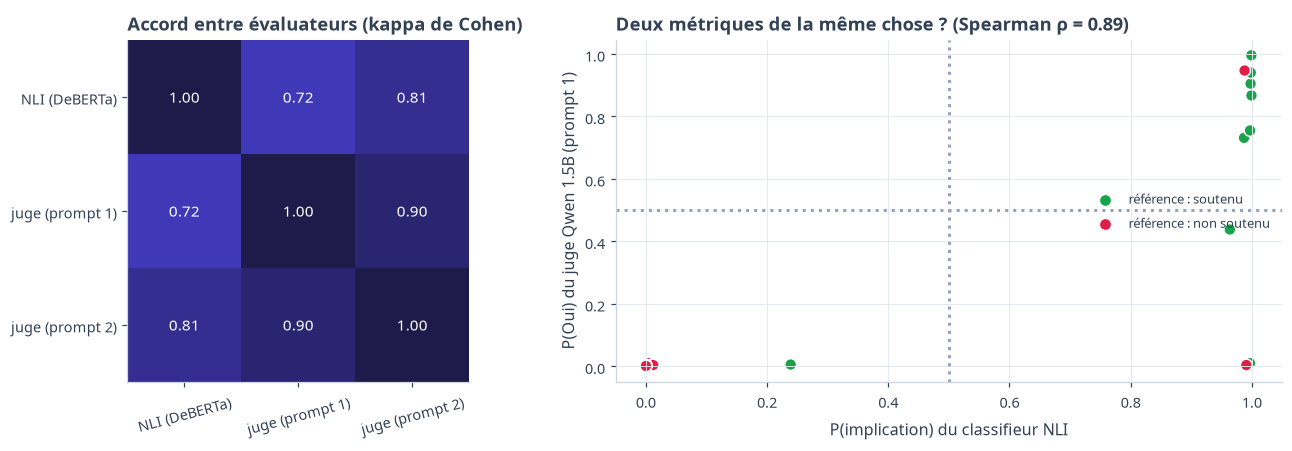

In [18]:
names = list(scorers)
K = np.array([[c4.cohen_kappa((scorers[a] > 0.5).astype(int), (scorers[b] > 0.5).astype(int)) for b in names] for a in names])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
im = axes[0].imshow(K, cmap="aie_seq", vmin=-0.2, vmax=1)
axes[0].set_xticks(range(3), names, rotation=15); axes[0].set_yticks(range(3), names); axes[0].grid(False)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{K[i, j]:.2f}", ha="center", va="center", color="white" if K[i, j] > 0.6 else SLATE)
axes[0].set_title("Accord entre évaluateurs (kappa de Cohen)")
ax = axes[1]
ax.scatter(claims.p_nli, claims["juge (prompt 1)"], c=np.where(y == 1, GREEN, ROSE), s=60, edgecolor="white")
rho = spearmanr(claims.p_nli, claims["juge (prompt 1)"])[0]
ax.axhline(0.5, color=GRAY, ls=":"); ax.axvline(0.5, color=GRAY, ls=":")
ax.set_xlabel("P(implication) du classifieur NLI"); ax.set_ylabel("P(Oui) du juge Qwen 1.5B (prompt 1)")
ax.scatter([], [], c=GREEN, label="référence : soutenu"); ax.scatter([], [], c=ROSE, label="référence : non soutenu")
ax.legend(loc="center right", fontsize=8.5)
ax.set_title(f"Deux métriques de la même chose ? (Spearman ρ = {rho:.2f})")
finish(fig)

Ce tableau est le cœur de la méta-évaluation : sur ce petit jeu, le classifieur NLI spécialisé
de 184 M paramètres fait au moins aussi bien que le juge généraliste de 1,5 milliard, pour une
fraction du coût, et le juge change d'avis selon la simple formulation de son prompt (accord
imparfait entre prompt 1 et prompt 2, exactitudes différentes). Avec 22 exemples, ces écarts
restent toutefois dans la marge d'incertitude (section 6). Le kappa de Cohen corrige l'accord du hasard :
$\kappa = (p_o - p_e)/(1 - p_e)$, où $p_o$ est l'accord observé et $p_e$ l'accord attendu
si les deux évaluateurs votaient au hasard avec leurs fréquences respectives.

**Fiabilité.** Un juge échantillonné à température 1 ne rend pas deux fois le même verdict.
À partir de $P(\text{Oui})$, simulons 10 relances échantillonnées et comptons les affirmations
dont le verdict change ; à température 0, le verdict est déterministe.

In [19]:
rng = np.random.default_rng(0)
p1 = claims["juge (prompt 1)"].values
runs = rng.random((10, len(p1))) < p1          # 10 relances à température 1
instables = (runs.any(0) & ~runs.all(0)).mean()
score_runs = ((runs.astype(int) == y).mean(1))
print(f"affirmations dont le verdict change au moins une fois sur 10 relances : {instables:.0%}")
print(f"exactitude du juge selon la relance : de {score_runs.min():.0%} à {score_runs.max():.0%} "
      f"(à température 0 : {((p1 > 0.5).astype(int) == y).mean():.0%}, à chaque fois)")

affirmations dont le verdict change au moins une fois sur 10 relances : 32%
exactitude du juge selon la relance : de 73% à 82% (à température 0 : 82%, à chaque fois)


D'où la consigne du livre : fixer la température du juge à 0 et **figer toute la
configuration** (modèle juge, prompt, paramètres d'échantillonnage). Enfin, l'évaluation a un
coût : ajouter un juge en ligne rallonge la latence de chaque réponse ; certaines équipes
sautent l'évaluation pour gagner du temps, ce que le livre qualifie de pari risqué.

> **À retenir.** Évaluez vos évaluateurs sur des exemples annotés (exactitude, kappa),
> mesurez leur accord mutuel et leur stabilité, fixez la température du juge à 0 et
> figez sa configuration.

## 8. Itérer et tracer les expériences (section *Iterate*)

Les besoins et les usages changent : critères, rubriques et exemples évoluent. Mais un
pipeline qui change sans cesse ne permet plus de comparer les résultats dans le temps. La
solution : **journaliser toutes les variables** d'une évaluation (version des données,
rubrique, prompt et paramètres du juge) et identifier chaque configuration par une empreinte.

In [20]:
base_cfg = dict(donnees="faits_mediatheque_v1", rubrique="coherence_-1_0_1_v2", juge=llm.MEDIUM,
                prompt_juge=judge_prompts["juge (prompt 1)"], temperature=0.0)
log = []
for change, cfg in [("référence", base_cfg),
                    ("nouveau prompt du juge", {**base_cfg, "prompt_juge": judge_prompts["juge (prompt 2)"]}),
                    ("température 1 (à éviter)", {**base_cfg, "temperature": 1.0}),
                    ("référence relancée", dict(base_cfg))]:
    col = "juge (prompt 2)" if cfg["prompt_juge"] == judge_prompts["juge (prompt 2)"] else "juge (prompt 1)"
    if cfg["temperature"] > 0:
        score = score_runs[0]          # un verdict échantillonné (relance n° 1 de la section 7)
    else:
        score = ((claims[col] > 0.5).astype(int) == y).mean()
    log.append(dict(empreinte=c4.experiment_fingerprint(cfg), changement=change, juge=cfg["juge"].split("/")[-1],
                    temperature=cfg["temperature"], exactitude_du_juge=round(score, 3)))
pd.DataFrame(log)

,empreinte,changement,juge,temperature,exactitude_du_juge
0,8336de68dc,référence,Qwen2.5-1.5B-Instruct,0.0,0.818
1,0393e8accb,nouveau prompt du juge,Qwen2.5-1.5B-Instruct,0.0,0.864
2,e6f0612d7b,température 1 (à éviter),Qwen2.5-1.5B-Instruct,1.0,0.773
3,8336de68dc,référence relancée,Qwen2.5-1.5B-Instruct,0.0,0.818


La relance de la configuration de référence retrouve la **même empreinte** : les deux
résultats sont comparables. Toute autre modification produit une nouvelle empreinte, ce qui
empêche de comparer par erreur des scores obtenus avec des pipelines différents.

> **À retenir.** Itérez sur le pipeline, mais sous suivi d'expériences : chaque score doit
> être rattaché à une configuration complète et identifiable.

## Synthèse

- **Étape 1** : évaluer chaque composant (pour savoir où le système échoue), par tour et par
  tâche (succès **et** nombre de tours).
- **Étape 2** : la ligne directrice est l'étape la plus importante : critères, rubrique avec
  exemples validée par des humains, correspondance avec les métriques métier et seuil d'utilité.
- **Étape 3** : une méthode par critère, mélange bon marché / coûteux, logprobs pour la
  confiance, humains en production ; données annotées, **découpées par tranches** (gare au
  paradoxe de Simpson), en nombre suffisant (bootstrap, $n \propto 1/\Delta^2$, évaluation
  appariée).
- **Méta-évaluation** : bons signaux, fiabilité (température 0), corrélations, coût.
- **Itérer** sous suivi d'expériences.

L'évaluation reviendra tout au long du livre : évaluation du RAG et des agents (chapitre 6),
qualité des données (chapitre 8), coûts et latence de l'inférence (chapitre 9), retours
utilisateurs (chapitre 10).

In [21]:
c4.load_nli.cache_clear()
llm.free_gpu()